In [1]:
import pandas as pd
import numpy as np
import re
from pathlib import Path
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from pathlib import Path

project_path = Path.cwd().parent

dataset_path = project_path / "data" / "raw" / "Womens Clothing E-Commerce Reviews.csv"

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


In [4]:
print("Total Rows and Columns:", df.shape)

Total Rows and Columns: (23486, 11)


In [5]:
print("Dataset Information:")
df.info()

print("\nMissing Values in Each Column:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Unnamed: 0               23486 non-null  int64
 1   Clothing ID              23486 non-null  int64
 2   Age                      23486 non-null  int64
 3   Title                    19676 non-null  str  
 4   Review Text              22641 non-null  str  
 5   Rating                   23486 non-null  int64
 6   Recommended IND          23486 non-null  int64
 7   Positive Feedback Count  23486 non-null  int64
 8   Division Name            23472 non-null  str  
 9   Department Name          23472 non-null  str  
 10  Class Name               23472 non-null  str  
dtypes: int64(6), str(5)
memory usage: 2.0 MB

Missing Values in Each Column:
Unnamed: 0                    0
Clothing ID                   0
Age                           0
Title                      3810

In [6]:
# Remove missing reviews
reviews = df["Review Text"].dropna()

# Calculate words in each review
word_counts = reviews.apply(lambda review: len(str(review).split()))

# Calculate average review length
average_length = word_counts.mean()

print("Total Reviews:", len(reviews))
print("Average Review Length:", round(average_length, 2), "words")

Total Reviews: 22641
Average Review Length: 60.2 words


In [7]:
# Create sentiment labels using Rating
def get_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positive"

# Apply sentiment function
df["Sentiment"] = df["Rating"].apply(get_sentiment)

# Count each sentiment
print(df["Sentiment"].value_counts())

Sentiment
Positive    18208
Neutral      2871
Negative     2407
Name: count, dtype: int64


In [8]:
# Select first 1000 non-empty reviews
sample_reviews = df["Review Text"].dropna().astype(str).head(1000)

# Combine reviews and convert to lowercase
all_text = " ".join(sample_reviews).lower()

# Extract words using regular expression
tokens = re.findall(r"\b\w+\b", all_text)

# Find unique words
types = set(tokens)

print("Total Tokens:", len(tokens))
print("Unique Types (Vocabulary Size):", len(types))

Total Tokens: 61962
Unique Types (Vocabulary Size): 3667


In [9]:
from collections import Counter

# Count frequency of each token
word_frequency = Counter(tokens)

# Get 20 most common words
most_common_words = word_frequency.most_common(20)

# Display results
for word, count in most_common_words:
    print(word, ":", count)

the : 3412
i : 2894
it : 2198
and : 2173
a : 1923
is : 1365
this : 1113
to : 1085
in : 940
but : 719
on : 656
for : 611
of : 610
with : 588
so : 554
was : 551
that : 466
not : 458
my : 448
s : 411


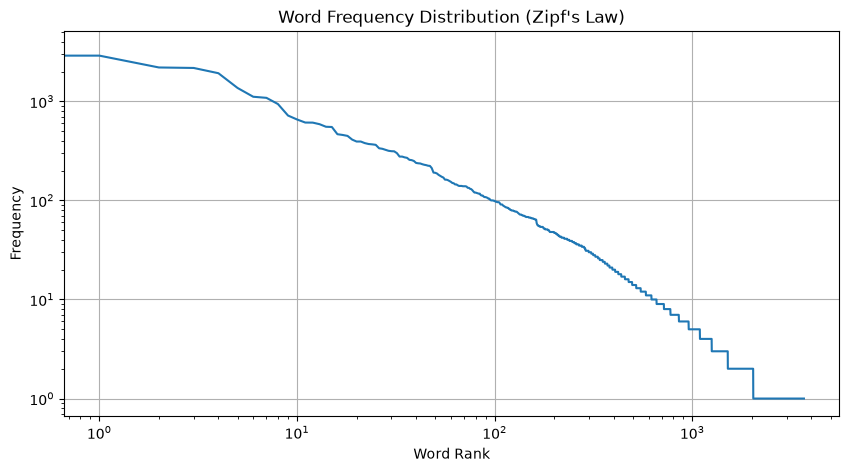

In [10]:
import matplotlib.pyplot as plt

# Get word frequencies in descending order
frequencies = sorted(word_frequency.values(), reverse=True)

# Plot Zipf's Law graph
plt.figure(figsize=(10, 5))
plt.plot(frequencies)

plt.title("Word Frequency Distribution (Zipf's Law)")
plt.xlabel("Word Rank")
plt.ylabel("Frequency")
plt.yscale("log")
plt.xscale("log")
plt.grid(True)

plt.show()

In [11]:
# Display 5 original customer reviews
messy_examples = df["Review Text"].dropna().head(5)

for i, review in enumerate(messy_examples, start=1):
    print(f"\nExample {i}:")
    print(review)
    print("-" * 80)


Example 1:
Absolutely wonderful - silky and sexy and comfortable
--------------------------------------------------------------------------------

Example 2:
Love this dress!  it's sooo pretty.  i happened to find it in a store, and i'm glad i did bc i never would have ordered it online bc it's petite.  i bought a petite and am 5'8".  i love the length on me- hits just a little below the knee.  would definitely be a true midi on someone who is truly petite.
--------------------------------------------------------------------------------

Example 3:
I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my usual size) but i found this to be outrageously small. so small in fact that i could not zip it up! i reordered it in petite medium, which was just ok. overall, the top half was comfortable and fit nicely, but the bottom half had a very tight under layer and several somewhat cheap (net) over layers. imo, a major design flaw was

In [12]:
# Regex Tokenizer
def regex_tokenizer(text):
    return re.findall(r"\b\w+\b", str(text).lower())

# Test on one customer review
sample_text = df["Review Text"].dropna().iloc[0]

print("Original Review:")
print(sample_text)

print("\nRegex Tokens:")
print(regex_tokenizer(sample_text))

Original Review:
Absolutely wonderful - silky and sexy and comfortable

Regex Tokens:
['absolutely', 'wonderful', 'silky', 'and', 'sexy', 'and', 'comfortable']


In [13]:
import nltk
from nltk.tokenize import word_tokenize

# Download tokenizer data
nltk.download("punkt")
nltk.download("punkt_tab")

# Select one review
sample_text = df["Review Text"].dropna().iloc[0]

# Apply NLTK tokenizer
nltk_tokens = word_tokenize(sample_text.lower())

print("Original Review:")
print(sample_text)

print("\nNLTK Tokens:")
print(nltk_tokens)

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Original Review:
Absolutely wonderful - silky and sexy and comfortable

NLTK Tokens:
['absolutely', 'wonderful', '-', 'silky', 'and', 'sexy', 'and', 'comfortable']


In [14]:
# Compare both tokenization methods

regex_tokens = regex_tokenizer(sample_text)

print("Original Review:")
print(sample_text)

print("\nRegex Tokenizer Output:")
print(regex_tokens)

print("\nNLTK Tokenizer Output:")
print(nltk_tokens)

print("\nNumber of Regex Tokens:", len(regex_tokens))
print("Number of NLTK Tokens:", len(nltk_tokens))

Original Review:
Absolutely wonderful - silky and sexy and comfortable

Regex Tokenizer Output:
['absolutely', 'wonderful', 'silky', 'and', 'sexy', 'and', 'comfortable']

NLTK Tokenizer Output:
['absolutely', 'wonderful', '-', 'silky', 'and', 'sexy', 'and', 'comfortable']

Number of Regex Tokens: 7
Number of NLTK Tokens: 8


In [15]:
# Regex Pattern 1: Remove URLs
url_pattern = r"https?://\S+|www\.\S+"

# Regex Pattern 2: Remove HTML tags
html_pattern = r"<[^>]+>"

# Regex Pattern 3: Remove extra whitespace
whitespace_pattern = r"\s+"

# Test all three patterns
test_text = "Great product! Visit www.example.com <b>Nice</b>   quality."

cleaned_text = re.sub(url_pattern, "", test_text)
cleaned_text = re.sub(html_pattern, "", cleaned_text)
cleaned_text = re.sub(whitespace_pattern, " ", cleaned_text).strip()

print("Original Text:")
print(test_text)

print("\nCleaned Text:")
print(cleaned_text)

Original Text:
Great product! Visit www.example.com <b>Nice</b>   quality.

Cleaned Text:
Great product! Visit Nice quality.


Dataset-Specific Tokenization Challenges
1. Punctuation and Special Characters

Customer reviews contain punctuation marks such as commas, full stops, exclamation marks and question marks. These can affect word tokenization.

2. Contractions and Apostrophes

Reviews may contain words such as "don't", "isn't" and "it's". Tokenizers may split these words differently, which can affect their meaning.

3. Hyphenated Words

Words connected with hyphens can create tokenization differences because some tokenizers split them into separate words.

In [16]:
import unicodedata

def clean_text(text):

    # Handle missing values
    if pd.isna(text):
        return ""

    # Convert text to string
    text = str(text)

    # Step 1: Unicode normalization
    text = unicodedata.normalize("NFC", text)

    # Step 2: Convert to lowercase
    text = text.lower()

    # Step 3: Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", "", text)

    # Step 4: Remove HTML tags
    text = re.sub(r"<[^>]+>", "", text)

    # Step 5: Remove special characters and punctuation
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Step 6: Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


print("Text cleaning function created successfully!")

Text cleaning function created successfully!


In [17]:
# Test cleaning function on 5 reviews

for review in df["Review Text"].dropna().head(5):
    print("ORIGINAL:")
    print(review)

    print("\nCLEANED:")
    print(clean_text(review))

    print("-" * 60)

ORIGINAL:
Absolutely wonderful - silky and sexy and comfortable

CLEANED:
absolutely wonderful silky and sexy and comfortable
------------------------------------------------------------
ORIGINAL:
Love this dress!  it's sooo pretty.  i happened to find it in a store, and i'm glad i did bc i never would have ordered it online bc it's petite.  i bought a petite and am 5'8".  i love the length on me- hits just a little below the knee.  would definitely be a true midi on someone who is truly petite.

CLEANED:
love this dress it s sooo pretty i happened to find it in a store and i m glad i did bc i never would have ordered it online bc it s petite i bought a petite and am 5 8 i love the length on me hits just a little below the knee would definitely be a true midi on someone who is truly petite
------------------------------------------------------------
ORIGINAL:
I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my usual size) b

In [18]:
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords")

# Load English stopwords
stop_words = set(stopwords.words("english"))

# Keep important negative words
stop_words.discard("not")
stop_words.discard("no")
stop_words.discard("nor")

print("Total Stopwords:", len(stop_words))
print("Stopwords loaded successfully!")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...


Total Stopwords: 195
Stopwords loaded successfully!


[nltk_data]   Unzipping corpora\stopwords.zip.


In [19]:
from nltk.stem import WordNetLemmatizer

nltk.download("wordnet")
nltk.download("omw-1.4")

lemmatizer = WordNetLemmatizer()

# Test lemmatization
words = ["running", "products", "cars", "studies"]

for word in words:
    print(word, "→", lemmatizer.lemmatize(word))

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...


running → running
products → product
cars → car
studies → study


In [20]:
import pandas as pd
import re

# Load cleaned dataset
cleaned_df = pd.read_csv("../data/processed/cleaned_reviews.csv")

# Original reviews
original_text = " ".join(df["Review Text"].dropna().astype(str)).lower()

# Cleaned reviews
cleaned_text = " ".join(cleaned_df["Cleaned Review"].dropna().astype(str))

# Count unique words
original_vocab = set(re.findall(r"\b\w+\b", original_text))
cleaned_vocab = set(re.findall(r"\b\w+\b", cleaned_text))

print("Vocabulary Before Cleaning:", len(original_vocab))
print("Vocabulary After Cleaning:", len(cleaned_vocab))
print("Vocabulary Reduction:", len(original_vocab) - len(cleaned_vocab))

Vocabulary Before Cleaning: 14183
Vocabulary After Cleaning: 11312
Vocabulary Reduction: 2871


In [21]:
print("Dataset Shape:", df.shape)

print("\nAverage Review Length:",
      round(df["Review Text"].dropna().apply(
          lambda x: len(str(x).split())
      ).mean(), 2))

print("\nSentiment Distribution:")
print(df["Sentiment"].value_counts())

print("\nTokens:", len(tokens))
print("Unique Types:", len(types))

Dataset Shape: (23486, 12)

Average Review Length: 60.2

Sentiment Distribution:
Sentiment
Positive    18208
Neutral      2871
Negative     2407
Name: count, dtype: int64

Tokens: 61962
Unique Types: 3667
